<a href="https://colab.research.google.com/github/mariaalejandragg31-tech/Codigo1/blob/main/Quiz3_SerieTiempo_TickerAsignado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quiz 3 · Análisis de una serie de tiempo financiera

**Estudiante:** Maria Alejandra Guisao Gomez
**Ticker asignado:** QQQ
**Activo analizado:** QQQ  
**Periodo de análisis:** FECHA_INICIO = "2024-01-01"
FECHA_FIN = "2026-10-01"

## Propósito
Analizar el comportamiento histórico de una serie de tiempo financiera mediante visualización, rendimientos, volatilidad y una proyección de corto plazo.

> Este análisis tiene fines académicos y no constituye una recomendación de inversión.

## 0. Configuración
Escriba su ticker exactamente como aparece en S22. No lo cambie: la entrega se revisa contra el ticker asignado.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

TICKER = "QQQ"
FECHA_INICIO = "2024-01-01"
FECHA_FIN = "2026-10-01"

## 1. Contexto del activo
Indique qué activo representa el ticker, en qué mercado se negocia, su moneda y por qué es relevante analizarlo. Cite la fuente.

El activo analizado es **QQQ**, un fondo cotizado en bolsa (ETF) que busca replicar el desempeño del índice Nasdaq-100. Este índice reúne empresas no financieras de gran capitalización que cotizan en Nasdaq, con una importante participación de compañías de tecnología y otros sectores de crecimiento.

QQQ se negocia en el mercado estadounidense Nasdaq y sus precios se expresan en dólares estadounidenses (USD). Es relevante para el análisis de series de tiempo porque permite estudiar la evolución del mercado de grandes empresas de crecimiento, calcular sus rendimientos diarios, observar la volatilidad y examinar su comportamiento histórico.


## 2. Descarga de datos
Descargue al menos dos años de precios diarios.

In [ ]:

# Descargar precios diarios de QQQ
datos = yf.download(
    TICKER,
    start=FECHA_INICIO,
    end=FECHA_FIN,
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Verificar que la descarga tenga información
if datos.empty:
    raise ValueError("No se descargaron datos. Revisa el ticker o las fechas.")

# Mostrar las primeras y últimas observaciones
print("Primeras observaciones:")
display(datos.head())

print("Últimas observaciones:")
display(datos.tail())

print("Columnas descargadas:")
print(datos.columns)



Primeras observaciones:


Price,Close,High,Low,Open,Volume
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ
Date,,,,,
2024-01-02,396.840637,400.290654,394.524191,400.044224,58026900
2024-01-03,392.641541,395.273424,392.207852,394.218697,47002800
2024-01-04,390.620758,393.883486,390.403899,390.778477,39432800
2024-01-05,391.084045,393.853914,389.694178,390.788342,44922800
2024-01-08,399.167023,399.452860,392.158543,392.306395,42473800


Últimas observaciones:


Price,Close,High,Low,Open,Volume
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ
Date,,,,,
2026-09-24,741.099976,742.659973,734.619995,735.289978,29000900
2026-09-25,744.500000,745.919983,739.640015,742.830017,30283800
2026-09-28,736.530029,741.419983,731.630005,740.460022,41775000
2026-09-29,737.929993,740.580017,735.340027,740.150024,27052300
2026-09-30,739.770020,745.099976,739.460022,740.190002,29820400


Columnas descargadas:
MultiIndex([( 'Close', 'QQQ'),
            (  'High', 'QQQ'),
            (   'Low', 'QQQ'),
            (  'Open', 'QQQ'),
            ('Volume', 'QQQ')],
           names=['Price', 'Ticker'])


## 3. Calidad de datos
Revise periodo real, frecuencia, número de observaciones, valores faltantes y duplicados.

In [ ]:

# Preparar la serie de precios de cierre
if isinstance(datos.columns, pd.MultiIndex):
    cierre = datos["Close"][TICKER]
else:
    cierre = datos["Close"]

cierre = cierre.squeeze().copy()
cierre = pd.to_numeric(cierre, errors="coerce")
cierre = cierre.sort_index()

# Revisar la calidad de los datos
print("Número de observaciones:", len(cierre))
print("Fecha inicial:", cierre.index.min())
print("Fecha final:", cierre.index.max())
print("Frecuencia: diaria, según los días de negociación")
print("Valores faltantes:", cierre.isna().sum())
print("Fechas duplicadas:", cierre.index.duplicated().sum())

# Limpieza de la serie
cierre = cierre[~cierre.index.duplicated(keep="first")]
cierre = cierre.dropna()

print("\nDespués de la limpieza:")
print("Observaciones válidas:", len(cierre))
print("Valores faltantes:", cierre.isna().sum())
print("Fechas duplicadas:", cierre.index.duplicated().sum())



Número de observaciones: 689
Fecha inicial: 2024-01-02 00:00:00
Fecha final: 2026-09-30 00:00:00
Frecuencia: diaria, según los días de negociación
Valores faltantes: 0
Fechas duplicadas: 0

Después de la limpieza:
Observaciones válidas: 689
Valores faltantes: 0
Fechas duplicadas: 0


**Interpretación de la calidad de los datos**

La serie de tiempo financiera de QQQ contiene 689 observaciones diarias, comprendidas entre el 2 de enero de 2024 y el 30 de septiembre de 2026. Durante la revisión de calidad se identificó que no existen valores faltantes ni fechas duplicadas.

Después de realizar el proceso de limpieza, se conservaron las 689 observaciones válidas. No fue necesario eliminar registros por datos faltantes ni por fechas duplicadas, ya que la serie se encontraba completa y organizada correctamente.

La frecuencia de los datos es diaria, de acuerdo con los días de negociación del mercado bursátil. Por lo tanto, la información es adecuada para continuar con el análisis de la evolución de los precios, el cálculo de los rendimientos diarios y la estimación de la volatilidad de QQQ.

## 4. Serie de precios
Grafique el precio de cierre en el tiempo, con título, ejes y fuente.

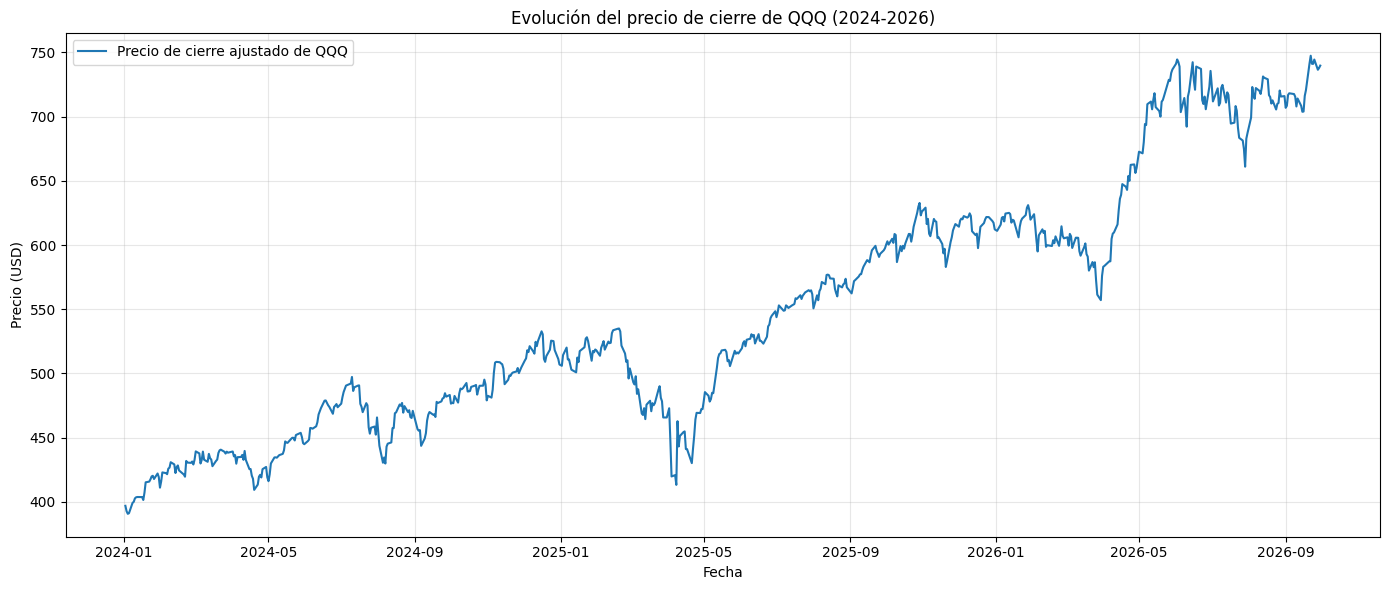

In [ ]:

plt.figure(figsize=(14, 6))

plt.plot(
    cierre.index,
    cierre.values,
    label="Precio de cierre ajustado de QQQ",
    linewidth=1.5
)

plt.title("Evolución del precio de cierre de QQQ (2024-2026)")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [ ]:

fecha_max = cierre.idxmax()
fecha_min = cierre.idxmin()

print("Precio máximo:", round(cierre.max(), 2), "USD")
print("Fecha del máximo:", fecha_max.date())

print("Precio mínimo:", round(cierre.min(), 2), "USD")
print("Fecha del mínimo:", fecha_min.date())

print("Precio inicial:", round(cierre.iloc[0], 2), "USD")
print("Precio final:", round(cierre.iloc[-1], 2), "USD")

variacion_total = (cierre.iloc[-1] / cierre.iloc[0] - 1) * 100
print("Variación total del periodo:", round(variacion_total, 2), "%")


Precio máximo: 747.46 USD
Fecha del máximo: 2026-09-22
Precio mínimo: 390.62 USD
Fecha del mínimo: 2024-01-04
Precio inicial: 396.84 USD
Precio final: 739.77 USD
Variación total del periodo: 86.41 %


## 5. Lectura temporal
Interpretación de la evolución del precio de cierre de QQQ
El gráfico muestra una tendencia general creciente en el precio de cierre ajustado del ETF QQQ durante el periodo comprendido entre enero de 2024 y septiembre de 2026. Al inicio del periodo, el precio se encontraba cerca de los 390 USD, mientras que al final alcanzó aproximadamente los 740 USD, lo que evidencia una valorización importante durante el periodo analizado.
- Tendencia: Se observa una tendencia alcista a largo plazo, aunque se presentan varias fluctuaciones y caídas temporales.
- Máximos: Los precios más altos se observan hacia septiembre de 2026, cuando el valor se acerca a los 745 USD.
- Mínimos: El precio más bajo se presenta al inicio de 2024, cerca de los 390 USD. También se observan caídas importantes alrededor de agosto de 2024, abril de 2025 y abril de 2026.
- Cambios relevantes: Durante 2024 el precio aumentó progresivamente, aunque tuvo algunas caídas. A comienzos de 2025 presentó un descenso pronunciado y posteriormente se recuperó. Desde mediados de 2025 continuó una tendencia ascendente. En abril de 2026 se observa otra caída importante, seguida de una recuperación rápida que llevó el precio a niveles superiores a los anteriores.

## 6. Rendimientos diarios
Calcule los rendimientos diarios, presente su resumen estadístico y grafíquelos.

Resumen estadístico de los rendimientos diarios:


,Rendimiento diario
count,688.000000
mean,0.000991
std,0.013132
min,-0.062109
25%,-0.005041
50%,0.001443
75%,0.008065
max,0.120031


Media diaria (%): 0.0991
Desviación estándar diaria (%): 1.3132
Rendimiento diario máximo (%): 12.0031
Rendimiento diario mínimo (%): -6.2109


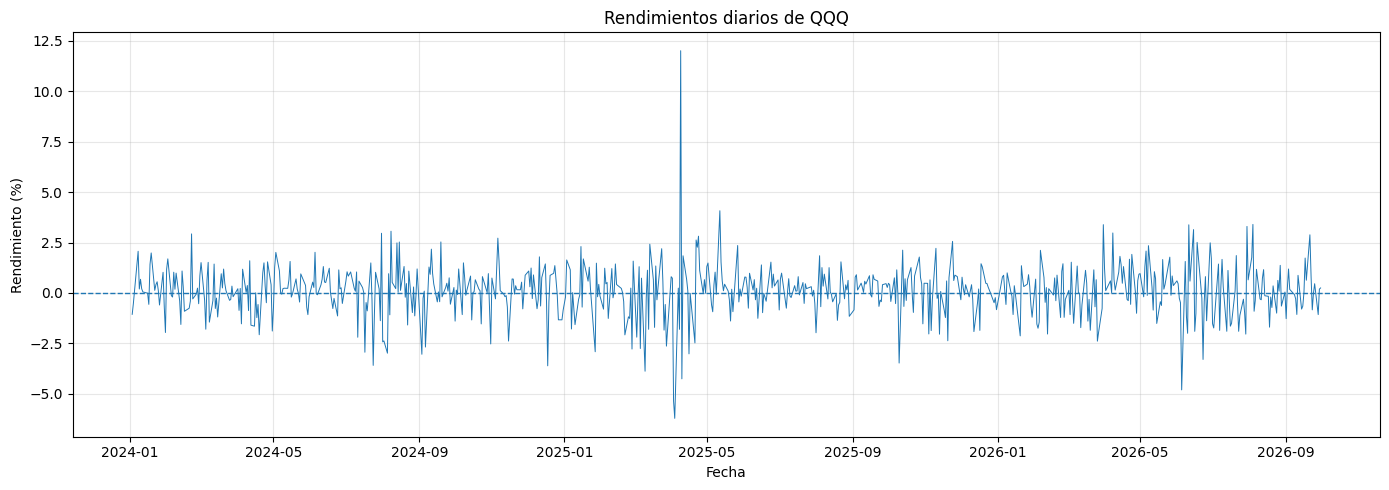

In [ ]:

# Calcular rendimientos diarios
rendimientos = cierre.pct_change().dropna()

# Resumen estadístico
print("Resumen estadístico de los rendimientos diarios:")
display(rendimientos.describe().to_frame("Rendimiento diario"))

print("Media diaria (%):", round(rendimientos.mean() * 100, 4))
print("Desviación estándar diaria (%):", round(rendimientos.std() * 100, 4))
print("Rendimiento diario máximo (%):", round(rendimientos.max() * 100, 4))
print("Rendimiento diario mínimo (%):", round(rendimientos.min() * 100, 4))

# Gráfica de rendimientos diarios
plt.figure(figsize=(14, 5))
plt.plot(rendimientos.index, rendimientos.values * 100, linewidth=0.7)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Rendimientos diarios de QQQ")
plt.xlabel("Fecha")
plt.ylabel("Rendimiento (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 7. Volatilidad móvil
Calcule la volatilidad móvil de 20 días y grafíquela.

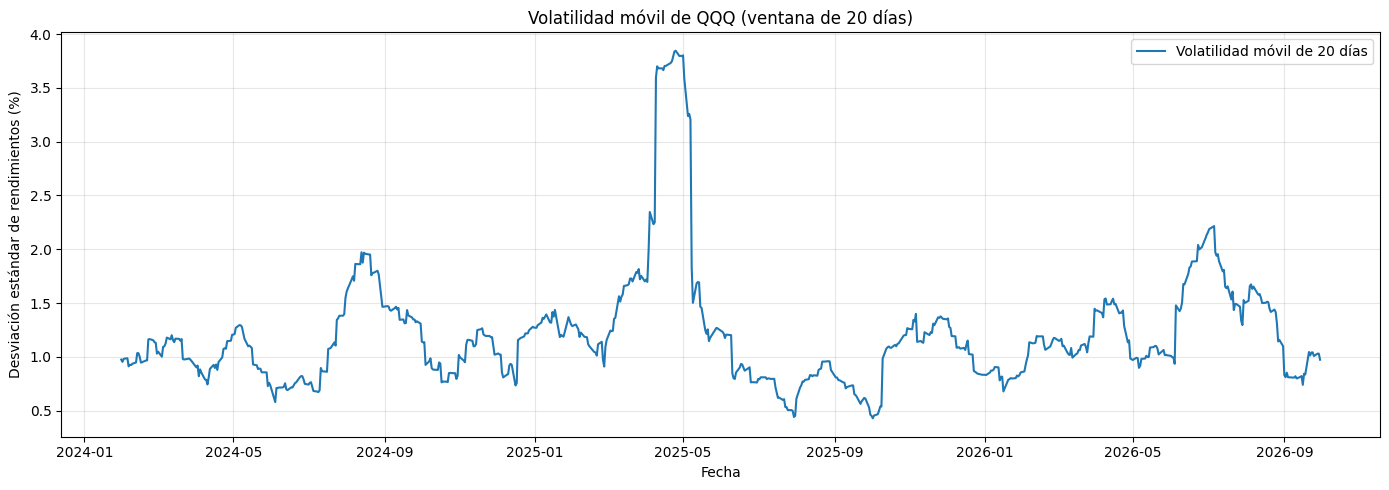

Volatilidad diaria promedio (%): 1.2119
Volatilidad diaria máxima (%): 3.8462
Fecha de volatilidad máxima: 2025-04-25


In [ ]:

# Calcular volatilidad móvil de 20 días
volatilidad = rendimientos.rolling(window=20).std()

# Gráfica de volatilidad
plt.figure(figsize=(14, 5))
plt.plot(
    volatilidad.index,
    volatilidad.values * 100,
    label="Volatilidad móvil de 20 días"
)

plt.title("Volatilidad móvil de QQQ (ventana de 20 días)")
plt.xlabel("Fecha")
plt.ylabel("Desviación estándar de rendimientos (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Volatilidad diaria promedio (%):",
      round(volatilidad.mean() * 100, 4))
print("Volatilidad diaria máxima (%):",
      round(volatilidad.max() * 100, 4))
print("Fecha de volatilidad máxima:",
      volatilidad.idxmax().date())



## 8. Visualización complementaria
Construya una tercera visualización pertinente (promedio móvil, distribución de rendimientos, comparación mensual u otra) y justifique su elección.

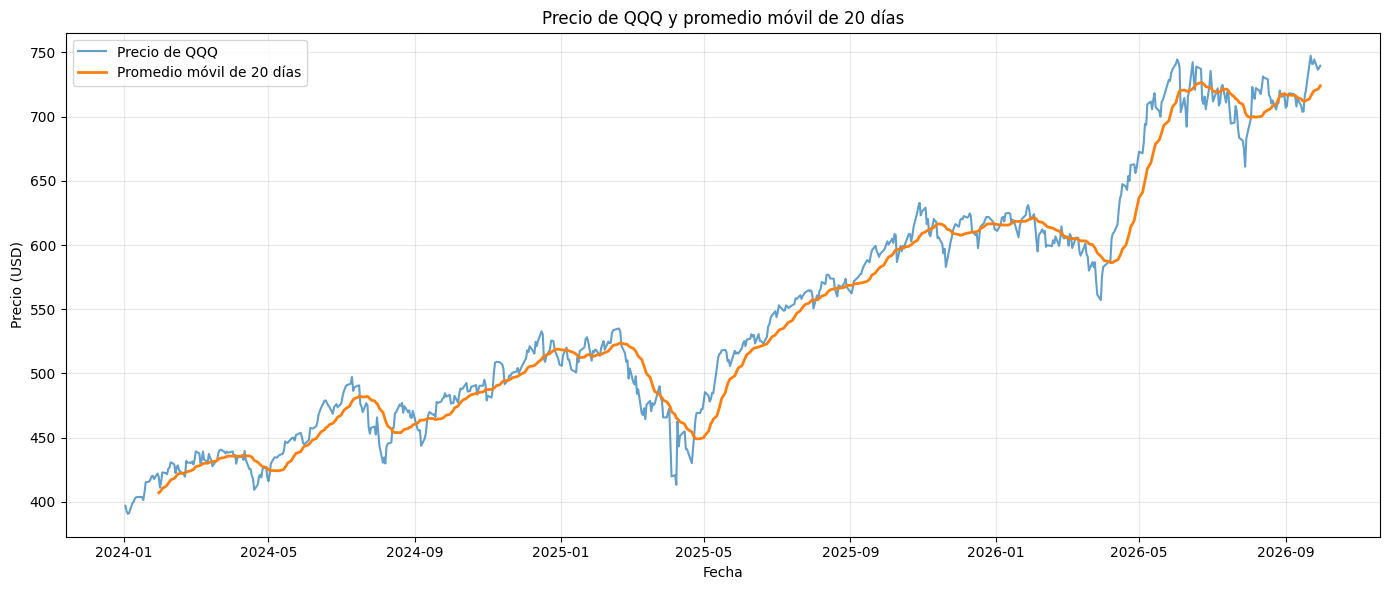

In [ ]:

# Calcular promedio móvil de 20 días
promedio_movil = cierre.rolling(window=20).mean()

# Comparar precio y promedio móvil
plt.figure(figsize=(14, 6))
plt.plot(cierre.index, cierre.values, label="Precio de QQQ", alpha=0.7)
plt.plot(
    promedio_movil.index,
    promedio_movil.values,
    label="Promedio móvil de 20 días",
    linewidth=2
)

plt.title("Precio de QQQ y promedio móvil de 20 días")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Se eligió el promedio móvil de 20 días como visualización complementaria porque permite comparar el precio diario de QQQ con una medida suavizada de su comportamiento reciente. Esto facilita observar cambios de tendencia y reduce el efecto visual de las fluctuaciones de corto plazo. Sin embargo, el promedio móvil utiliza datos pasados y puede reaccionar con retraso ante cambios del mercado.

## 9. Proyección corta
Plantee una proyección sencilla de corto plazo (por ejemplo, promedio móvil o regresión lineal) y explique sus limitaciones.

Último precio observado: 739.77 USD
Promedio de los últimos 20 días: 724.1 USD

Proyección de referencia:


,Precio proyectado (USD)
2026-10-01,724.1
2026-10-02,724.1
2026-10-05,724.1
2026-10-06,724.1
2026-10-07,724.1


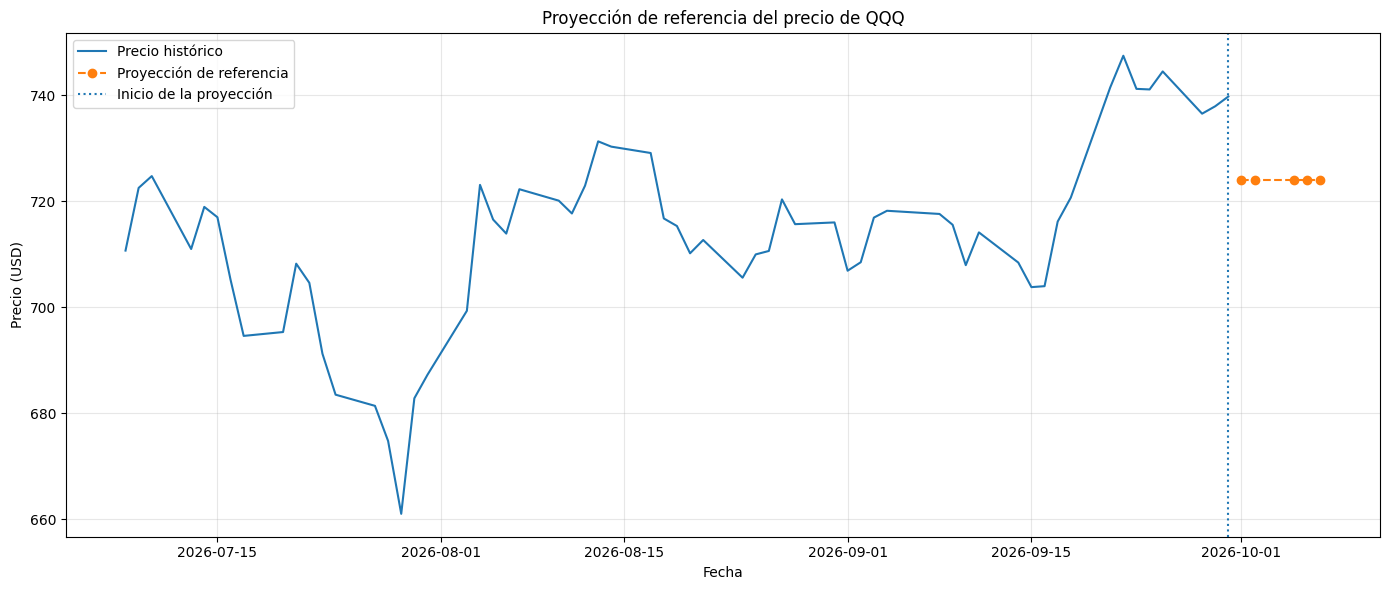

In [ ]:

# Proyección sencilla con el promedio de los últimos 20 precios
ventana = 20
horizonte = 5

if len(cierre) < ventana:
    raise ValueError("No hay suficientes datos para realizar la proyección.")

promedio_20 = cierre.tail(ventana).mean()

# Generar fechas futuras aproximadas de días hábiles
fechas_futuras = pd.bdate_range(
    start=cierre.index[-1] + pd.offsets.BDay(1),
    periods=horizonte
)

# Mantener como referencia el promedio de los últimos 20 días
proyeccion = pd.Series(
    promedio_20,
    index=fechas_futuras
)

print("Último precio observado:", round(cierre.iloc[-1], 2), "USD")
print("Promedio de los últimos 20 días:", round(promedio_20, 2), "USD")
print("\nProyección de referencia:")
display(proyeccion.to_frame(name="Precio proyectado (USD)").round(2))

# Mostrar los últimos 60 días y la proyección
plt.figure(figsize=(14, 6))

plt.plot(
    cierre.tail(60).index,
    cierre.tail(60).values,
    label="Precio histórico"
)

plt.plot(
    proyeccion.index,
    proyeccion.values,
    marker="o",
    linestyle="--",
    label="Proyección de referencia"
)

plt.axvline(
    cierre.index[-1],
    linestyle=":",
    label="Inicio de la proyección"
)

plt.title("Proyección de referencia del precio de QQQ")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Se realizó una proyección de corto plazo utilizando el promedio de los últimos 20 precios de cierre de QQQ. Este método ofrece una referencia sencilla para los siguientes cinco días hábiles aproximados.

La proyección mantiene un valor constante y no incorpora cambios futuros en las condiciones del mercado. Por ello, no representa una predicción precisa del precio futuro ni una recomendación de inversión. Sus resultados deben interpretarse con cautela, especialmente porque los precios financieros pueden cambiar rápidamente.

### 10. Conclusión financiera

**1. Comportamiento del precio:** Durante el periodo comprendido entre enero de 2024 y septiembre de 2026, el ETF QQQ presentó una tendencia general alcista. Según la gráfica, su precio pasó de aproximadamente 390 USD al inicio del periodo a cerca de 740 USD al final. Aunque se presentaron caídas importantes, el precio logró recuperarse y alcanzar niveles superiores, lo que evidencia una valorización significativa durante el periodo analizado.

**2. Riesgo y volatilidad:** El comportamiento del precio muestra que QQQ experimentó fluctuaciones y caídas en diferentes momentos, por lo que su evolución no fue constante. El análisis de los rendimientos diarios y de la volatilidad móvil de 20 días permite evaluar con mayor precisión la variabilidad del activo e identificar periodos de mayor incertidumbre. Por tanto, aunque la tendencia histórica fue positiva, existe un riesgo asociado a los cambios en el precio.

**3. Limitaciones del análisis y proyección:** La proyección de corto plazo permite establecer una referencia del posible comportamiento del precio a partir de los datos históricos y del método utilizado. Sin embargo, no garantiza que el precio futuro siga ese comportamiento, ya que el mercado puede verse afectado por factores económicos, financieros y noticias. Además, el análisis se limita al periodo estudiado y no constituye por sí solo una recomendación de inversión.



## 11. Video de sustentación
Pegue el enlace de su video individual (máximo 5 minutos). En el video explique su activo, sus gráficos y sus conclusiones.
https://drive.google.com/file/d/1YWj-t_OnI-Q5hgPzhHRm6dD7q3lCF2OZ/view?usp=drivesdk